In [1]:
import torch                                           # PyTorch: tensors + training
from torch import nn  
import pandas as pd
import matplotlib.pyplot as plt

X shape: torch.Size([100, 2])   y shape: torch.Size([100, 1])
epoch   0:  loss = 3031.2
epoch  50:  loss = 192.1
epoch 100:  loss = 97.7
epoch 150:  loss = 74.2
epoch 200:  loss = 62.5
epoch 250:  loss = 54.9


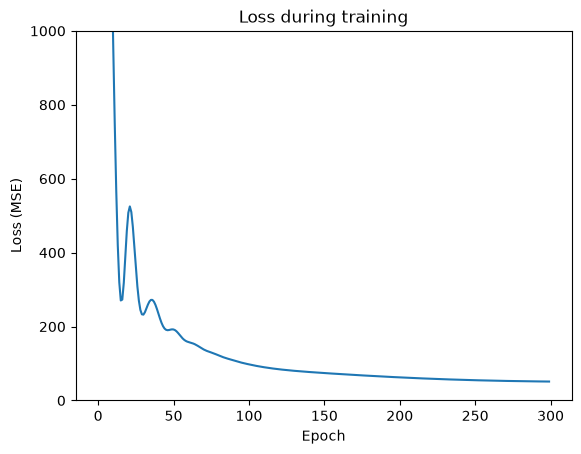

3 study hours, 2 phone hours → 61.0 marks


In [5]:
# 1. inputs and real answers
students = pd.read_csv("students_100.csv")      # read the file: one row per student

X = torch.tensor(                               # make a tensor (PyTorch's array) for the inputs
    students[["study_hours", "phone_hours"]].values,   # 2 columns → .values = only the numbers (a NumPy array)
    dtype=torch.float32,                        # decimal numbers: networks always use decimals
)
y = torch.tensor(                               # make a tensor for the real answers
    students[["maths"]].values,                 # [["maths"]] (2 brackets) = 1 column, shape (100, 1)
    dtype=torch.float32,
)
print("X shape:", X.shape, "  y shape:", y.shape)   # (100, 2) and (100, 1)

# 2. the map: 2 inputs → 3 hidden (ReLU) → 1 output
torch.manual_seed(42)                           # the same "random" starting weights for everyone
model = nn.Sequential(                          # put the layers in a row, left → right
    nn.Linear(2, 3),                            # 2 inputs → 3 hidden neurons (6 weights + 3 biases)
    nn.ReLU(),                                                                       # activation: negative → 0
    nn.Linear(3, 1),                            # 3 hidden neurons → 1 output (3 weights + 1 bias)
)
loss_fn = nn.MSELoss()                          # loss = average of (guess − real)²
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)   # the one who changes the weights. lr = step size

# 3. training loop
losses = []                                     # save the loss of every epoch, to draw it later
for epoch in range(300):                        # 300 epochs = 300 rounds through all the students
    guess = model(X)                            # 1. guess: forward pass for all 100 students
    loss = loss_fn(guess, y)                    # 2. how wrong: one number
    optimizer.zero_grad()                       # 3. clear old blame (gradients from the last round)
    loss.backward()                             # 4. find blame: backpropagation finds the GRADIENT of every weight                                   #    gradient = which way to change the weight (and how much) to make the loss smaller
    optimizer.step()                            # 5. fix: every weight takes one small step downhill
    losses.append(loss.item())                  # save this epoch's loss (.item() = the number out of the tensor)
    if epoch % 50 == 0:                         # print only every 50 epochs (0, 50, 100 ...)
        print(f"epoch {epoch:3}:  loss = {loss.item():.1f}")   # .item() = take the number out of the tensor

# 4. draw the loss curve: it should go DOWN
plt.plot(losses)                                # x = epoch, y = loss
plt.ylim(0, 1000)                               # zoom in: the first epochs are huge (about 3000)
plt.title("Loss during training")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.show()

# 5. use it
with torch.no_grad():                           # only guessing, no learning: don't track gradients
    new_student = torch.tensor([[3, 2]], dtype=torch.float32)   # 1 student: 3 study hours, 2 phone hours
    print("3 study hours, 2 phone hours →", round(model(new_student).item(), 1), "marks")